In [4]:
import pandas as pd

df = pd.read_excel("../data/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape


(541909, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [7]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

In [8]:
df[df["CustomerID"].isnull()].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,NaN,United Kingdom
1448,536544,21791,VINTAGE HEADS AND TAILS CARD GAME,2,2010-12-01 14:32:00,2.51,NaN,United Kingdom
1449,536544,21801,CHRISTMAS TREE DECORATION WITH BELL,10,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1450,536544,21802,CHRISTMAS TREE HEART DECORATION,9,2010-12-01 14:32:00,0.43,NaN,United Kingdom
1451,536544,21803,CHRISTMAS TREE STAR DECORATION,11,2010-12-01 14:32:00,0.43,NaN,United Kingdom


In [9]:
df[df["UnitPrice"] <= 0].shape

(2517, 8)

In [10]:
print("Zero prices:", (df["UnitPrice"] == 0).sum())

print("Negative prices:", (df["UnitPrice"] < 0).sum())

Zero prices: 2515
Negative prices: 2


In [11]:
df[df["UnitPrice"] < 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [12]:
df_clean = df[df["UnitPrice"] > 0].copy()

df_clean.shape

(539392, 8)

In [13]:
negative_quantity = df_clean[df_clean["Quantity"] < 0]

negative_quantity.shape

(9288, 8)

In [15]:
negative_quantity = df_clean[df_clean["Quantity"] < 0]

In [16]:
negative_quantity.shape


(9288, 8)

In [17]:
negative_quantity = df_clean[df_clean["Quantity"] < 0]

print("Negative Quantity Rows:", len(negative_quantity))

negative_quantity.head(10)

Negative Quantity Rows: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [18]:
cancelled = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled rows:", len(cancelled))


Cancelled rows: 9288


In [19]:
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

df_clean[["Quantity", "UnitPrice", "Revenue"]].head(10)

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [20]:
total_revenue = df_clean["Revenue"].sum()

print(f"Total Revenue: £{total_revenue:,.2f}")

Total Revenue: £9,769,872.05


In [21]:
gross_sales = df_clean.loc[
    df_clean["Quantity"] > 0, "Revenue"
].sum()

cancellations_value = -df_clean.loc[
    df_clean["Quantity"] < 0, "Revenue"
].sum()

print(f"Gross Sales: £{gross_sales:,.2f}")
print(f"Cancellations: £{cancellations_value:,.2f}")

Gross Sales: £10,666,684.54
Cancellations: £896,812.49


In [22]:
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

df_clean[["InvoiceDate", "YearMonth", "Revenue"]].head(10)


,InvoiceDate,YearMonth,Revenue
0,2010-12-01 08:26:00,2010-12,15.30
1,2010-12-01 08:26:00,2010-12,20.34
2,2010-12-01 08:26:00,2010-12,22.00
3,2010-12-01 08:26:00,2010-12,20.34
4,2010-12-01 08:26:00,2010-12,20.34
5,2010-12-01 08:26:00,2010-12,15.30
6,2010-12-01 08:26:00,2010-12,25.50
7,2010-12-01 08:28:00,2010-12,11.10
8,2010-12-01 08:28:00,2010-12,11.10
9,2010-12-01 08:34:00,2010-12,54.08


In [23]:
monthly_sales = df_clean.groupby("YearMonth")["Revenue"].sum()

monthly_sales

YearMonth
2010-12     748957.020
2011-01     560000.260
2011-02     498062.650
2011-03     683267.080
2011-04     493207.121
2011-05     723333.510
2011-06     691123.120
2011-07     681300.111
2011-08     704804.630
2011-09    1019687.622
2011-10    1070704.670
2011-11    1461756.250
2011-12     433668.010
Freq: M, Name: Revenue, dtype: float64

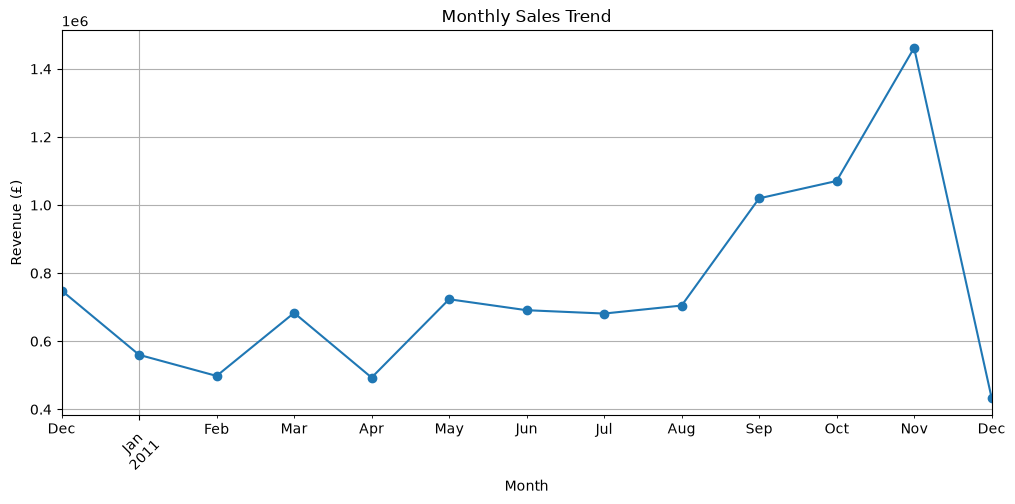

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)

plt.show()

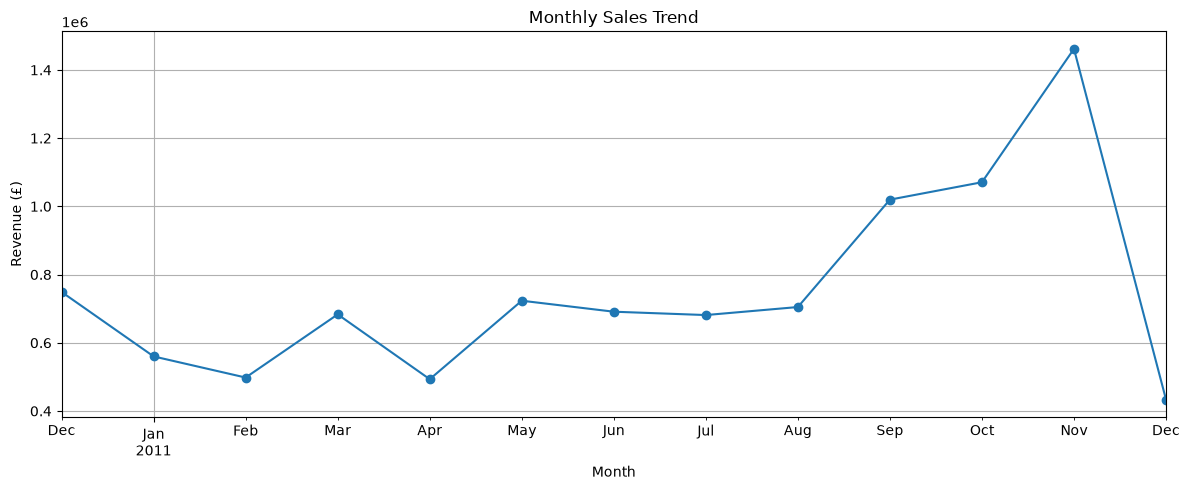

In [25]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path.cwd() / "images"
output_dir.mkdir(parents=True, exist_ok=True)

ax = monthly_sales.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.grid(True)

plt.tight_layout()
plt.savefig(output_dir / "monthly_sales.png", dpi=300)
plt.show()

In [26]:
top_products = (
    df_clean[
        (df_clean["Quantity"] > 0) &
        (df_clean["Description"].notna())
    ]
    .groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
Manual                                 78112.82
POSTAGE                                78101.88
RABBIT NIGHT LIGHT                     66964.99
Name: Revenue, dtype: float64

In [27]:
df_clean[
    df_clean["Description"].isin(
        ["DOTCOM POSTAGE", "POSTAGE", "Manual"]
    )
][["StockCode", "Description"]].drop_duplicates()

,StockCode,Description
45,POST,POSTAGE
1814,DOT,DOTCOM POSTAGE
2239,M,Manual
40383,m,Manual


In [28]:
excluded_codes = ["POST", "DOT", "M", "m"]

df_products = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Description"].notna()) &
    (~df_clean["StockCode"].isin(excluded_codes))
].copy()

top_products_clean = (
    df_products.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products_clean


Description
REGENCY CAKESTAND 3 TIER              174484.74
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106292.77
PARTY BUNTING                          99504.33
JUMBO BAG RED RETROSPOT                94340.05
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
RABBIT NIGHT LIGHT                     66964.99
PAPER CHAIN KIT 50'S CHRISTMAS         64952.29
ASSORTED COLOUR BIRD ORNAMENT          59094.93
CHILLI LIGHTS                          54117.76
Name: Revenue, dtype: float64

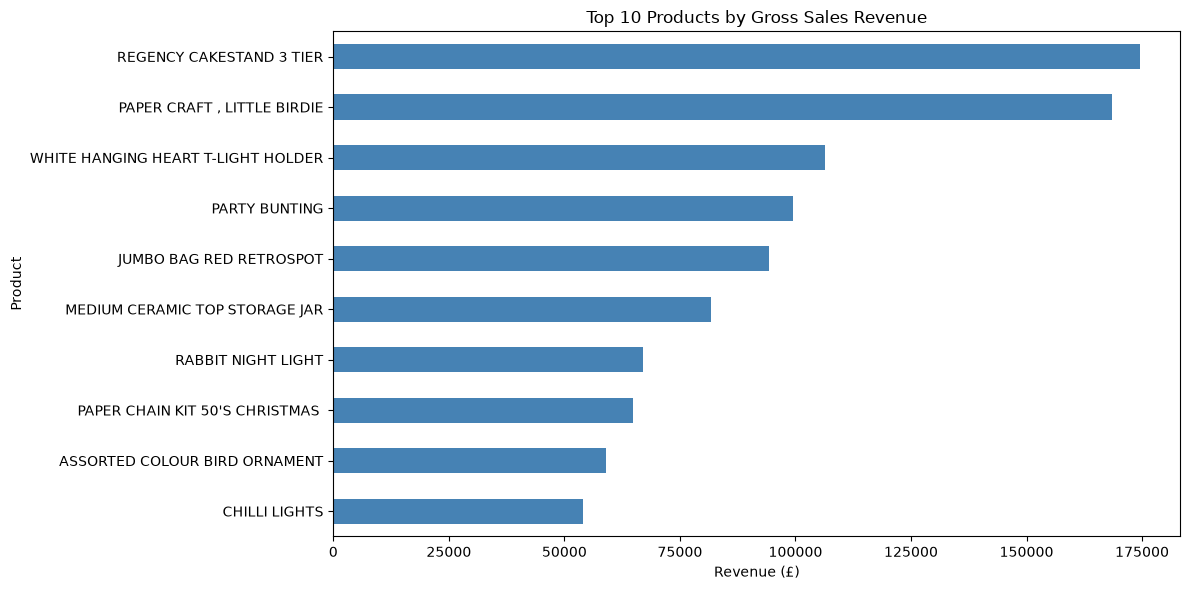

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

top_products_clean.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Products by Gross Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.tight_layout()
plt.show()

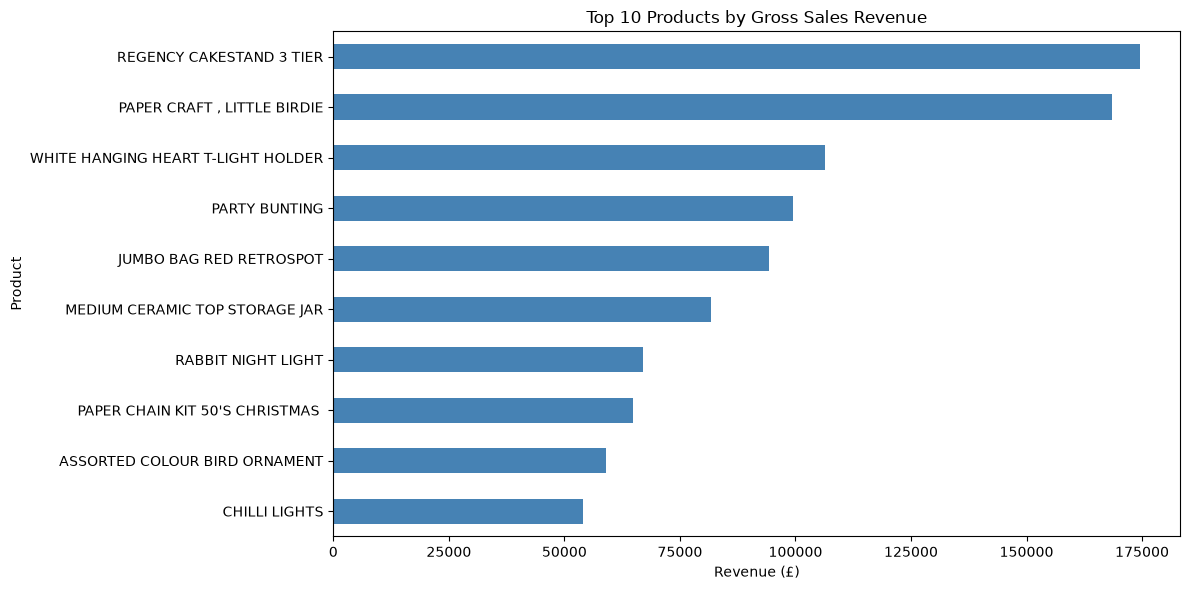

In [30]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path.cwd() / "images"
output_dir.mkdir(parents=True, exist_ok=True)

ax = top_products_clean.sort_values().plot(
    kind="barh",
    figsize=(12, 6),
    color="steelblue"
)

ax.set_title("Top 10 Products by Gross Sales Revenue")
ax.set_xlabel("Revenue (£)")
ax.set_ylabel("Product")

plt.tight_layout()

plt.savefig(
    output_dir / "top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
unique_customers = df_clean["CustomerID"].nunique()

print("Total Unique Customers:", unique_customers)

Total Unique Customers: 4371


In [32]:
top_customers = (
    df_clean[
        (df_clean["CustomerID"].notna()) &
        (df_clean["Quantity"] > 0)
    ]
    .groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194550.79
16446.0    168472.50
14911.0    143825.06
12415.0    124914.53
14156.0    117379.63
17511.0     91062.38
16029.0     81024.84
12346.0     77183.60
Name: Revenue, dtype: float64

In [33]:
customer_orders = df_clean[
    (df_clean["CustomerID"] == 14646) &
    (df_clean["Quantity"] > 0)
]["InvoiceNo"].nunique()

print("Number of Orders:", customer_orders)

Number of Orders: 73


In [34]:
customer_revenue = top_customers.loc[14646.0]

customer_aov = customer_revenue / customer_orders

print("Average Order Value: £", round(customer_aov, 2))

Average Order Value: £ 3838.44


In [35]:
top_frequent_customers = (
    df_clean[
        (df_clean["CustomerID"].notna()) &
        (df_clean["Quantity"] > 0)
    ]
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

top_frequent_customers

CustomerID
12748.0    209
14911.0    201
17841.0    124
13089.0     97
14606.0     93
15311.0     91
12971.0     86
14646.0     73
16029.0     63
13408.0     62
Name: InvoiceNo, dtype: int64

In [36]:
customer_12748 = df_clean[
    (df_clean["CustomerID"] == 12748) &
    (df_clean["Quantity"] > 0)
]

revenue_12748 = customer_12748["Revenue"].sum()

orders_12748 = customer_12748["InvoiceNo"].nunique()

aov_12748 = revenue_12748 / orders_12748

print("Revenue: £", round(revenue_12748, 2))
print("Orders:", orders_12748)
print("AOV: £", round(aov_12748, 2))

Revenue: £ 33719.73
Orders: 209
AOV: £ 161.34


In [37]:
customer_summary = (
    df_clean[
        (df_clean["CustomerID"].notna()) &
        (df_clean["Quantity"] > 0)
    ]
    .groupby("CustomerID")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique")
    )
)

customer_summary["AOV"] = (
    customer_summary["TotalRevenue"] /
    customer_summary["TotalOrders"]
)

customer_summary.head(10)

,TotalRevenue,TotalOrders,AOV
CustomerID,,,
12346.0,77183.60,1,77183.600000
12347.0,4310.00,7,615.714286
12348.0,1797.24,4,449.310000
12349.0,1757.55,1,1757.550000
12350.0,334.40,1,334.400000
12352.0,2506.04,8,313.255000
12353.0,89.00,1,89.000000
12354.0,1079.40,1,1079.400000
12355.0,459.40,1,459.400000


In [38]:
df_clean[
    df_clean["CustomerID"] == 12346
][
    ["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "Revenue"]
]

,InvoiceNo,InvoiceDate,Quantity,UnitPrice,Revenue
61619,541431,2011-01-18 10:01:00,74215,1.04,77183.6
61624,C541433,2011-01-18 10:17:00,-74215,1.04,-77183.6


In [39]:
customer_net_revenue = (
    df_clean[
        df_clean["CustomerID"].notna()
    ]
    .groupby("CustomerID")["Revenue"]
    .sum()
)

customer_net_revenue.loc[12346.0]

np.float64(0.0)

In [40]:
customer_summary["NetRevenue"] = customer_net_revenue

customer_summary[
    ["TotalRevenue", "NetRevenue", "TotalOrders", "AOV"]
].head(10)

,TotalRevenue,NetRevenue,TotalOrders,AOV
CustomerID,,,,
12346.0,77183.60,0.00,1,77183.600000
12347.0,4310.00,4310.00,7,615.714286
12348.0,1797.24,1797.24,4,449.310000
12349.0,1757.55,1757.55,1,1757.550000
12350.0,334.40,334.40,1,334.400000
12352.0,2506.04,1545.41,8,313.255000
12353.0,89.00,89.00,1,89.000000
12354.0,1079.40,1079.40,1,1079.400000
12355.0,459.40,459.40,1,459.400000


In [41]:
positive_customers = customer_summary[
    customer_summary["NetRevenue"] > 0
].copy()

print("Customers with positive Net Revenue:", len(positive_customers))

Customers with positive Net Revenue: 4322


In [42]:
positive_customers = customer_summary[
    customer_summary["NetRevenue"] > 0
].copy()

print("Customers with positive Net Revenue:", len(positive_customers))

Customers with positive Net Revenue: 4322


In [43]:
positive_customers["NetRevenue"].quantile(
    [0.25, 0.50, 0.75]
)

0.25     302.2925
0.50     657.5500
0.75    1625.7400
Name: NetRevenue, dtype: float64

In [44]:
import pandas as pd

positive_customers["Segment"] = pd.qcut(
    positive_customers["NetRevenue"],
    q=[0, 0.25, 0.75, 1],
    labels=["Low Value", "Medium Value", "High Value"]
)

positive_customers["Segment"].value_counts()

Segment
Medium Value    2160
Low Value       1081
High Value      1081
Name: count, dtype: int64

In [45]:
segment_revenue = positive_customers.groupby(
    "Segment", observed=True
)["NetRevenue"].sum()

segment_share = (
    segment_revenue / segment_revenue.sum() * 100
).round(2)

segment_share

Segment
Low Value        2.28
Medium Value    19.53
High Value      78.19
Name: NetRevenue, dtype: float64

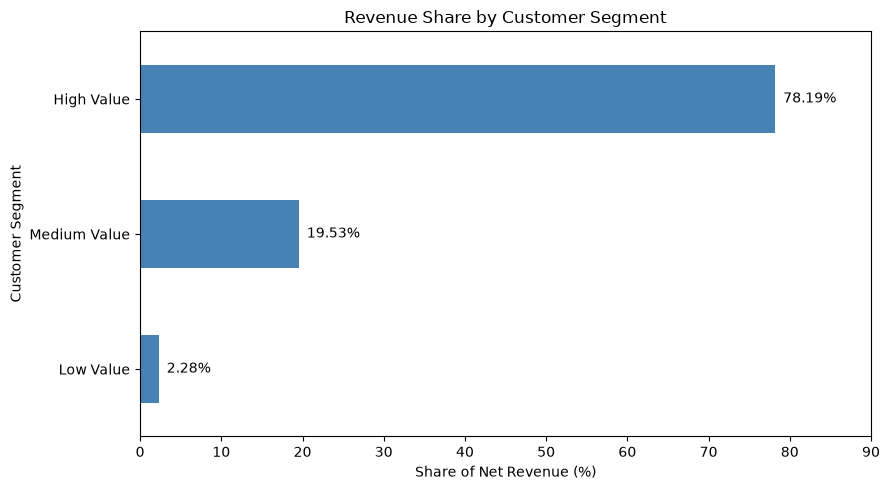

In [46]:
import matplotlib.pyplot as plt

ax = segment_share.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

ax.set_title("Revenue Share by Customer Segment")
ax.set_xlabel("Share of Net Revenue (%)")
ax.set_ylabel("Customer Segment")

for i, value in enumerate(segment_share.sort_values()):
    ax.text(value + 1, i, f"{value:.2f}%", va="center")

ax.set_xlim(0, 90)

plt.tight_layout()
plt.show()

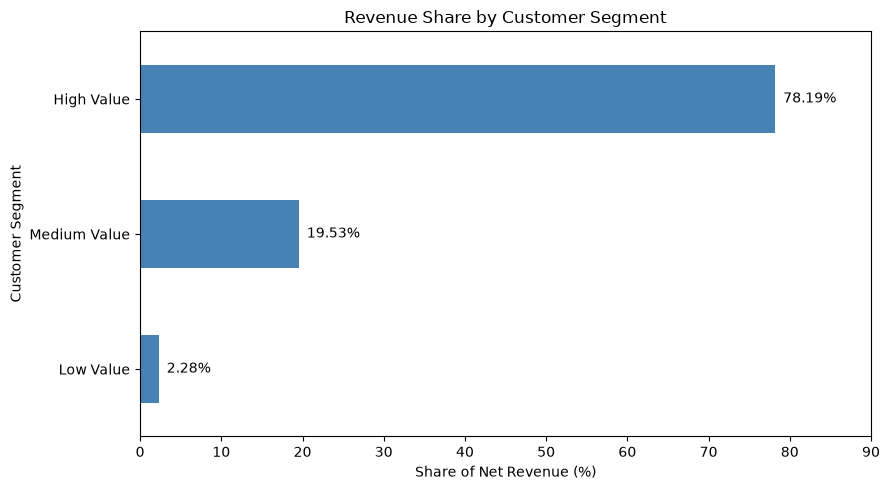

In [47]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path.cwd() / "images"
output_dir.mkdir(parents=True, exist_ok=True)

ax = segment_share.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

ax.set_title("Revenue Share by Customer Segment")
ax.set_xlabel("Share of Net Revenue (%)")
ax.set_ylabel("Customer Segment")

for i, value in enumerate(segment_share.sort_values()):
    ax.text(value + 1, i, f"{value:.2f}%", va="center")

ax.set_xlim(0, 90)

plt.tight_layout()

plt.savefig(
    output_dir / "customer_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
country_sales = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

country_sales

Country
United Kingdom    8209930.484
Netherlands        284661.540
EIRE               263276.820
Germany            221698.210
France             197403.900
Australia          137077.270
Switzerland         56385.350
Spain               54774.580
Belgium             40910.960
Sweden              36595.910
Name: Revenue, dtype: float64

In [49]:
uk_revenue = df_clean.loc[
    df_clean["Country"] == "United Kingdom",
    "Revenue"
].sum()

total_net_revenue = df_clean["Revenue"].sum()

uk_share = (uk_revenue / total_net_revenue) * 100

print("UK Revenue Share:", round(uk_share, 2), "%")

UK Revenue Share: 84.03 %


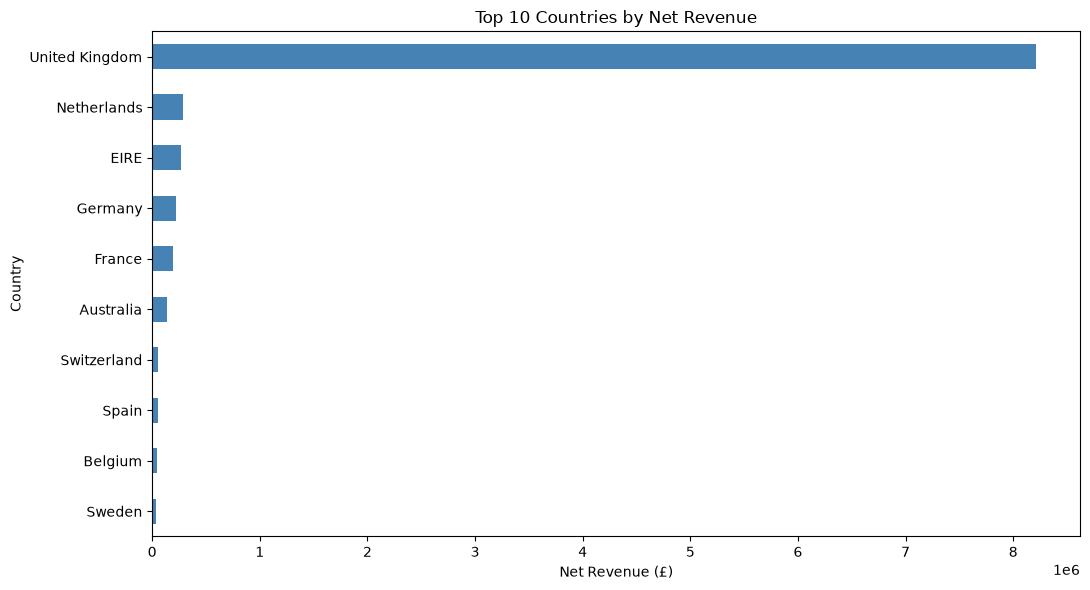

In [50]:
import matplotlib.pyplot as plt

ax = country_sales.sort_values().plot(
    kind="barh",
    figsize=(11, 6),
    color="steelblue"
)

ax.set_title("Top 10 Countries by Net Revenue")
ax.set_xlabel("Net Revenue (£)")
ax.set_ylabel("Country")

plt.tight_layout()
plt.show()

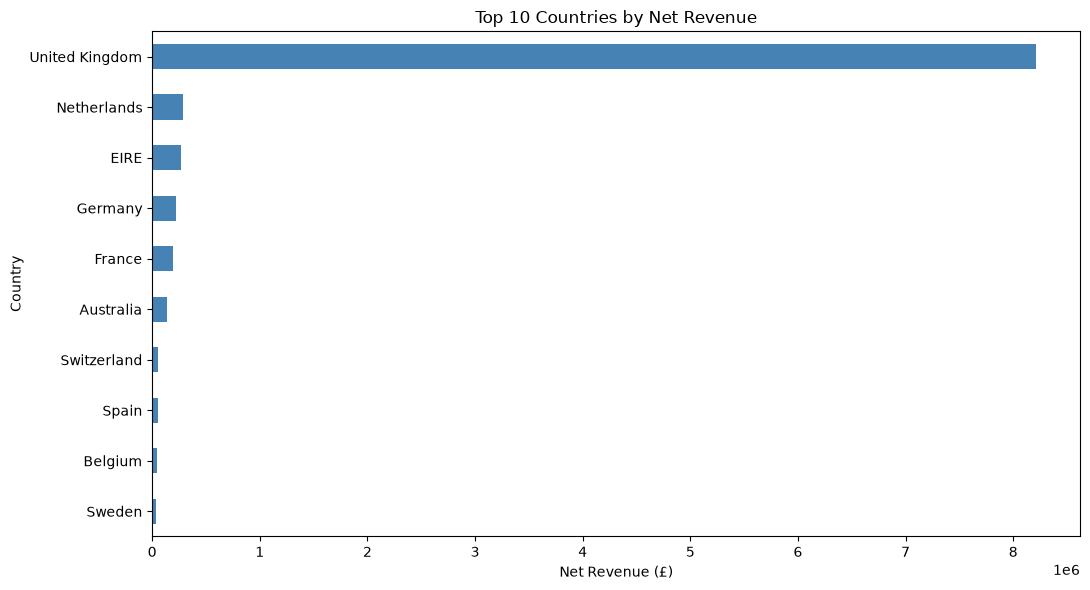

In [51]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path.cwd() / "images"
output_dir.mkdir(parents=True, exist_ok=True)

ax = country_sales.sort_values().plot(
    kind="barh",
    figsize=(11, 6),
    color="steelblue"
)

ax.set_title("Top 10 Countries by Net Revenue")
ax.set_xlabel("Net Revenue (£)")
ax.set_ylabel("Country")

plt.tight_layout()

plt.savefig(
    output_dir / "sales_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()